<a href="https://colab.research.google.com/github/239-blip/mssp607/blob/main/WeeklyModules/Week12/Week12_participation_239_blip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cloning into 'mssp607'...
remote: Enumerating objects: 225, done.
remote: Counting objects: 100% (225/225), done.
remote: Compressing objects: 100% (207/207), done.
remote: Total 225 (delta 100), reused 23 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (225/225), 9.09 MiB | 7.15 MiB/s, done.
Resolving deltas: 100% (100/100), done.
/content/mssp607/data
Male Completed: 174
All Students: 1000


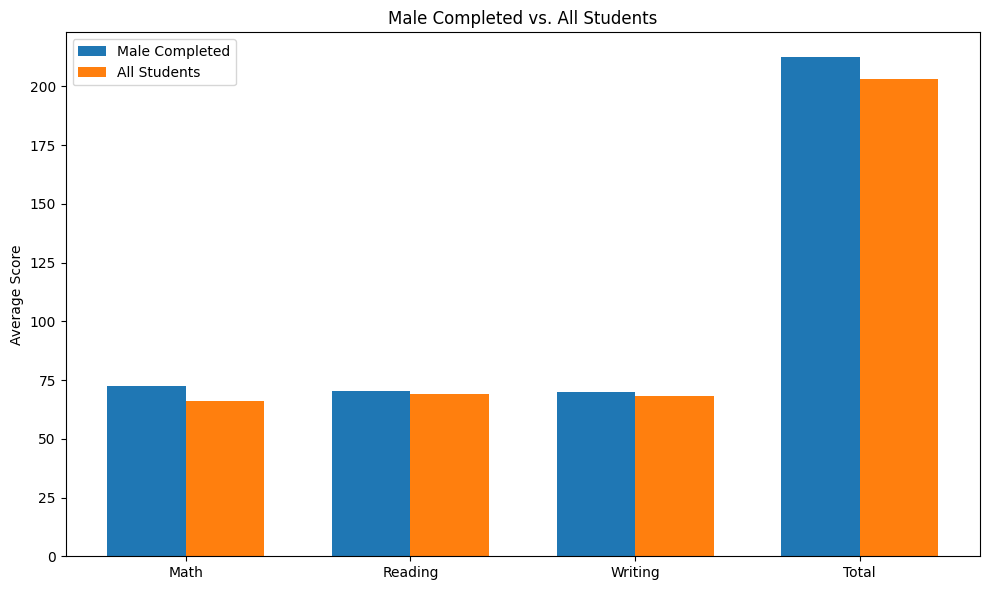

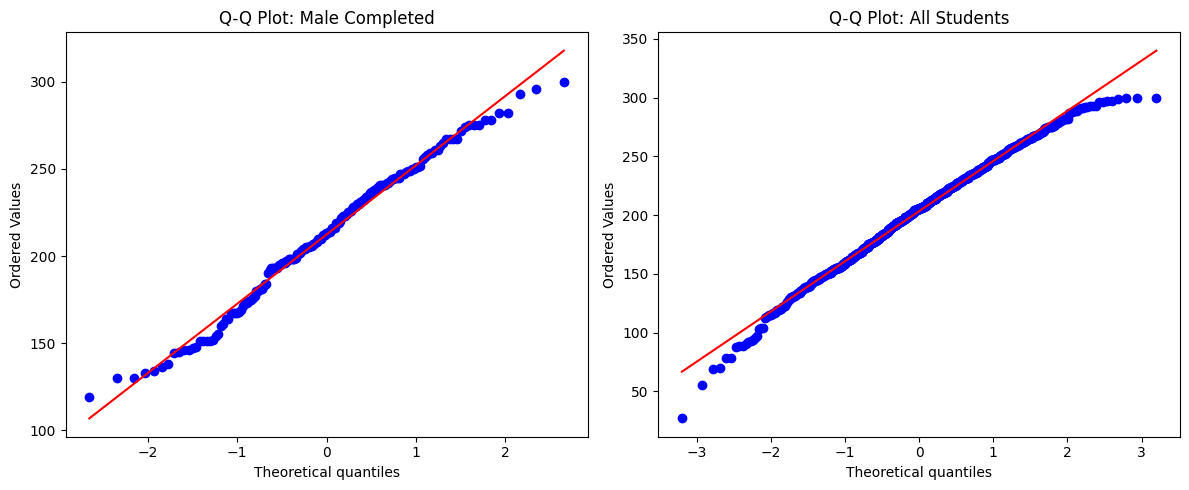

Male Completed Mean: 212.3448275862069
All Students Mean: 203.312
T-statistic: 2.7434020037502775
P-value: 0.006523424222628312
Numerical result: p < 0.05
Note: Groups overlap, so the independent
samples t-test p-value is not valid for
formal statistical inference.

Preparation Course
T-statistic: 8.5945
P-value: 0.000000

Gender
T-statistic: 4.1789
P-value: 0.000032

Lunch Type
T-statistic: 9.3232
P-value: 0.000000


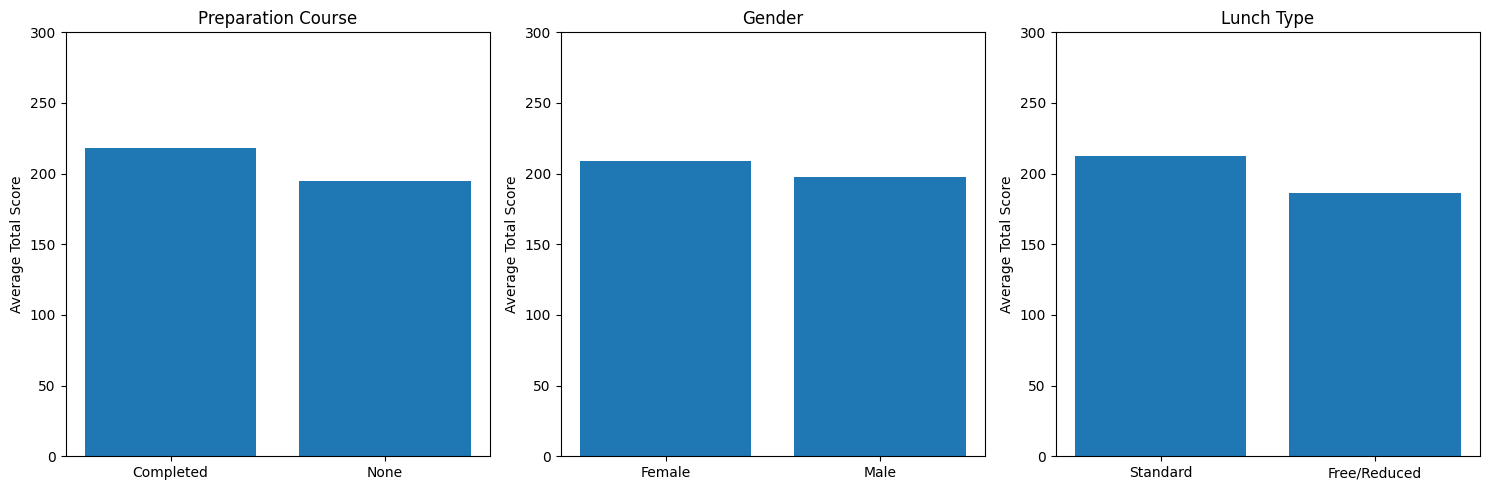

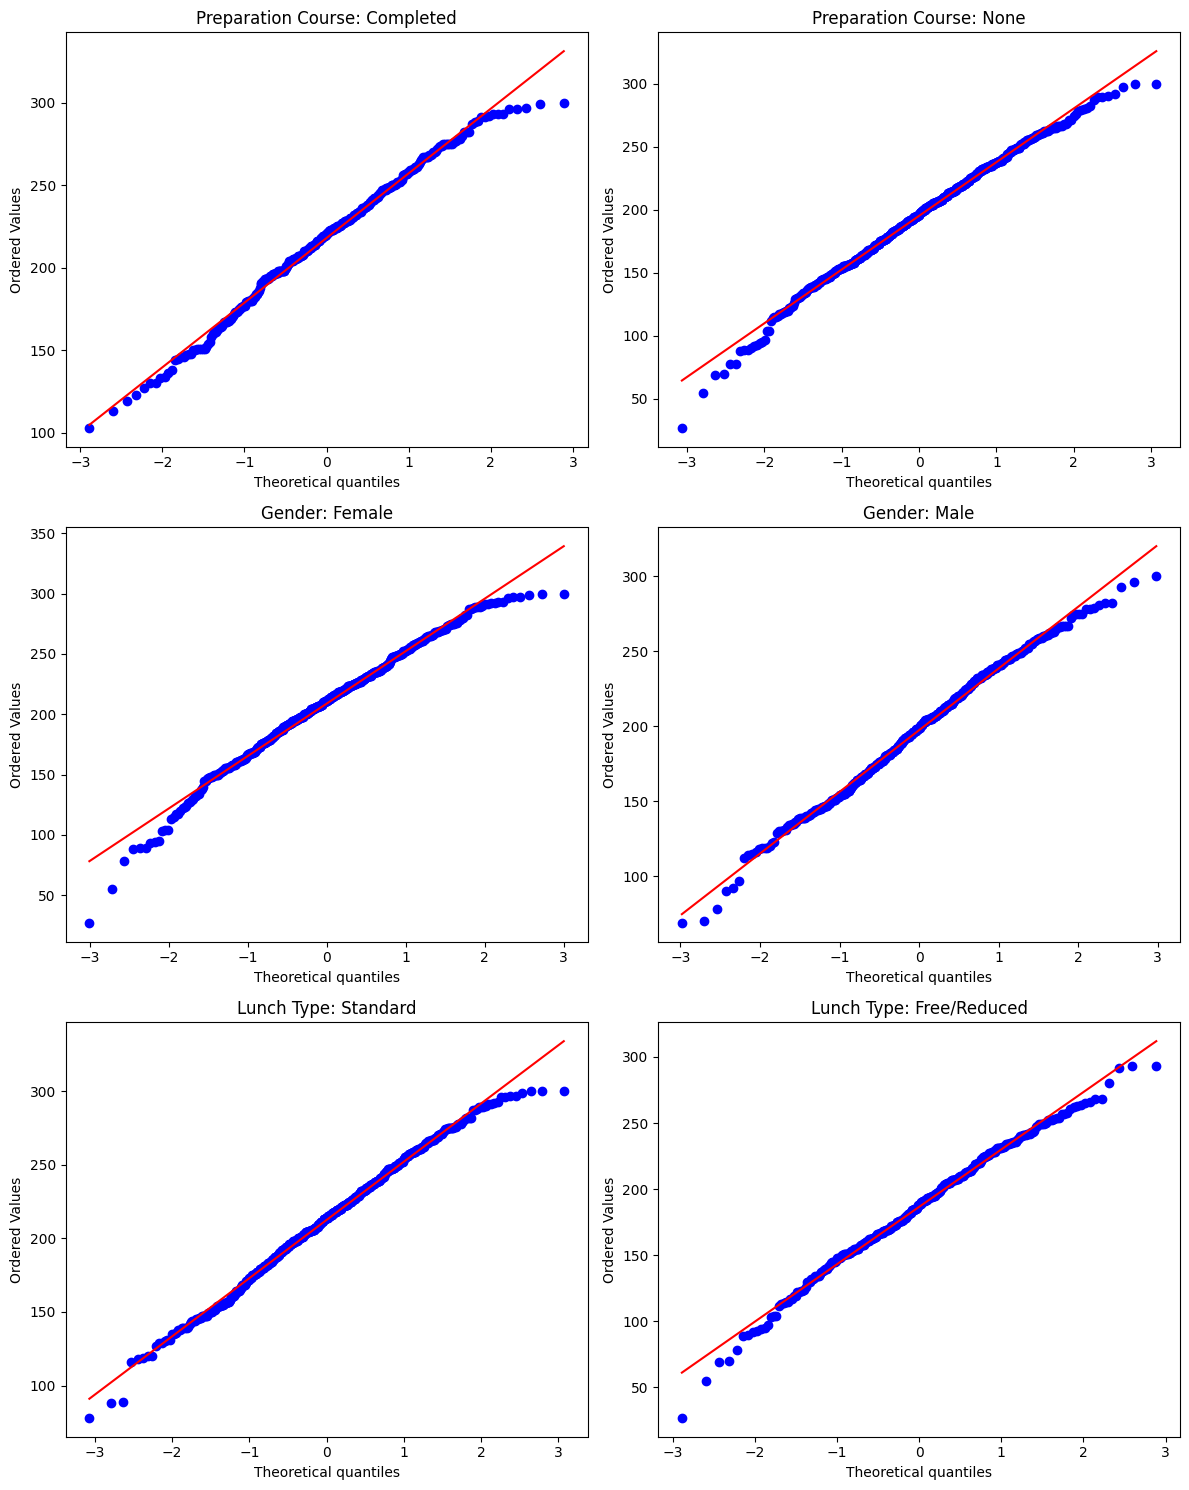

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

!git clone https://github.com/239-blip/mssp607.git
%cd /content/mssp607/data

df = pd.read_csv("Student Performance Data.csv")

male_completed = df[
    (df["gender"] == "male") &
    (df["test preparation course"] == "completed")
]

all_students = df

print("Male Completed:", len(male_completed))
print("All Students:", len(all_students))

# Calculate average scores
scores = ["math score", "reading score",
          "writing score", "total score"]

male_means = male_completed[scores].mean()
all_means = all_students[scores].mean()

# Create bar plot
x = np.arange(len(scores))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, male_means,
        width, label="Male Completed")

plt.bar(x + width/2, all_means,
        width, label="All Students")

plt.xticks(x, ["Math", "Reading", "Writing", "Total"])
plt.ylabel("Average Score")
plt.title("Male Completed vs. All Students")
plt.legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Male completed
stats.probplot(
    male_completed["total score"],
    dist="norm",
    plot=axes[0]
)
axes[0].set_title("Q-Q Plot: Male Completed")

# All students
stats.probplot(
    all_students["total score"],
    dist="norm",
    plot=axes[1]
)
axes[1].set_title("Q-Q Plot: All Students")

plt.tight_layout()
plt.show()

# Descriptive statistics
print("Male Completed Mean:",
      male_completed["total score"].mean())

print("All Students Mean:",
      all_students["total score"].mean())

# Welch's t-test (descriptive comparison only:
# the groups overlap, violating independence)
t_stat, p_value = stats.ttest_ind(
    male_completed["total score"],
    all_students["total score"],
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Numerical result: p < 0.05")
else:
    print("Numerical result: p >= 0.05")

print("Note: Groups overlap, so the independent")
print("samples t-test p-value is not valid for")
print("formal statistical inference.")


# Define groups
completed = df[
    df["test preparation course"] == "completed"
]
none = df[
    df["test preparation course"] == "none"
]

male = df[df["gender"] == "male"]
female = df[df["gender"] == "female"]

standard = df[df["lunch"] == "standard"]
reduced = df[df["lunch"] == "free/reduced"]

comparisons = [
    ("Preparation Course", completed, none,
     "Completed", "None"),
    ("Gender", female, male,
     "Female", "Male"),
    ("Lunch Type", standard, reduced,
     "Standard", "Free/Reduced")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (title, group1, group2, label1, label2) in zip(
    axes, comparisons
):
    means = [
        group1["total score"].mean(),
        group2["total score"].mean()
    ]

    ax.bar([label1, label2], means)
    ax.set_title(title)
    ax.set_ylabel("Average Total Score")
    ax.set_ylim(0, 300)

    t_stat, p_value = stats.ttest_ind(
        group1["total score"],
        group2["total score"],
        equal_var=False
    )

    print(f"\n{title}")
    print(f"T-statistic: {t_stat:.4f}")
    print(f"P-value: {p_value:.6f}")

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for i, (title, group1, group2, label1, label2) in enumerate(
    comparisons
):
    stats.probplot(
        group1["total score"],
        dist="norm",
        plot=axes[i, 0]
    )
    axes[i, 0].set_title(f"{title}: {label1}")

    stats.probplot(
        group2["total score"],
        dist="norm",
        plot=axes[i, 1]
    )
    axes[i, 1].set_title(f"{title}: {label2}")

plt.tight_layout()
plt.show()
